# Evaluación del detector de fallas

Este cuaderno entrena el detector con operación normal simulada, lo compara contra las alarmas por umbral en 80 escenarios con fallas y grafica un caso de deriva del transmisor de nivel.

Todo es reproducible: las semillas están fijas.

In [1]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent / "src"))

import matplotlib.pyplot as plt
import numpy as np
from IPython.display import Markdown

from analitica.detector import Detector
from analitica.entrenar import entrenar
from analitica.evaluar import a_markdown, evaluar
from planta.alarmas import GestorAlarmas
from planta.simulador import Planta

## 1. Entrenamiento con 3 horas de operación normal

Un operador simulado cambia la válvula y el setpoint de forma aleatoria; el modelo solo ve los residuos físicos.

In [2]:
detector = entrenar(horas=3.0, semilla=1)
print(f"Umbral Isolation Forest: {detector.umbral:.3f} | límite por residuo: {detector.limite_z:.1f} σ")

Umbral Isolation Forest: 0.611 | límite por residuo: 7.1 σ


## 2. Detector contra alarmas por umbral

20 escenarios por falla, con apertura y setpoint distintos, más 8 horas de operación normal para contar falsas detecciones.

In [3]:
resultados = evaluar(detector, escenarios=20, horas_normales=8)
Markdown(a_markdown(resultados))

| Falla | Detectadas por el modelo | Tiempo mediano del modelo | Diagnóstico correcto | Alarmas por umbral que sonaron | Tiempo mediano de la alarma |
|---|---|---|---|---|---|
| Sensor de nivel pegado | 19/20 | 127.5 s | 17/19 | 0/20 | nunca |
| Deriva del transmisor | 20/20 | 28.8 s | 19/20 | 2/20 | 891.0 s |
| Cavitación de la bomba | 20/20 | 3.8 s | 20/20 | 6/20 | 358.5 s |
| Válvula trabada | 20/20 | 28.5 s | 20/20 | 0/20 | nunca |

Falsas detecciones en 8 h de operación normal con cambios de setpoint y válvula: 0 (0.0 por hora).

## 3. Un caso: deriva del transmisor de nivel

El LT-101 empieza a leer de más. El PID, que confía en él, baja la velocidad de la bomba y el nivel real cae. La lectura sigue en el setpoint, así que ninguna alarma de nivel suena.

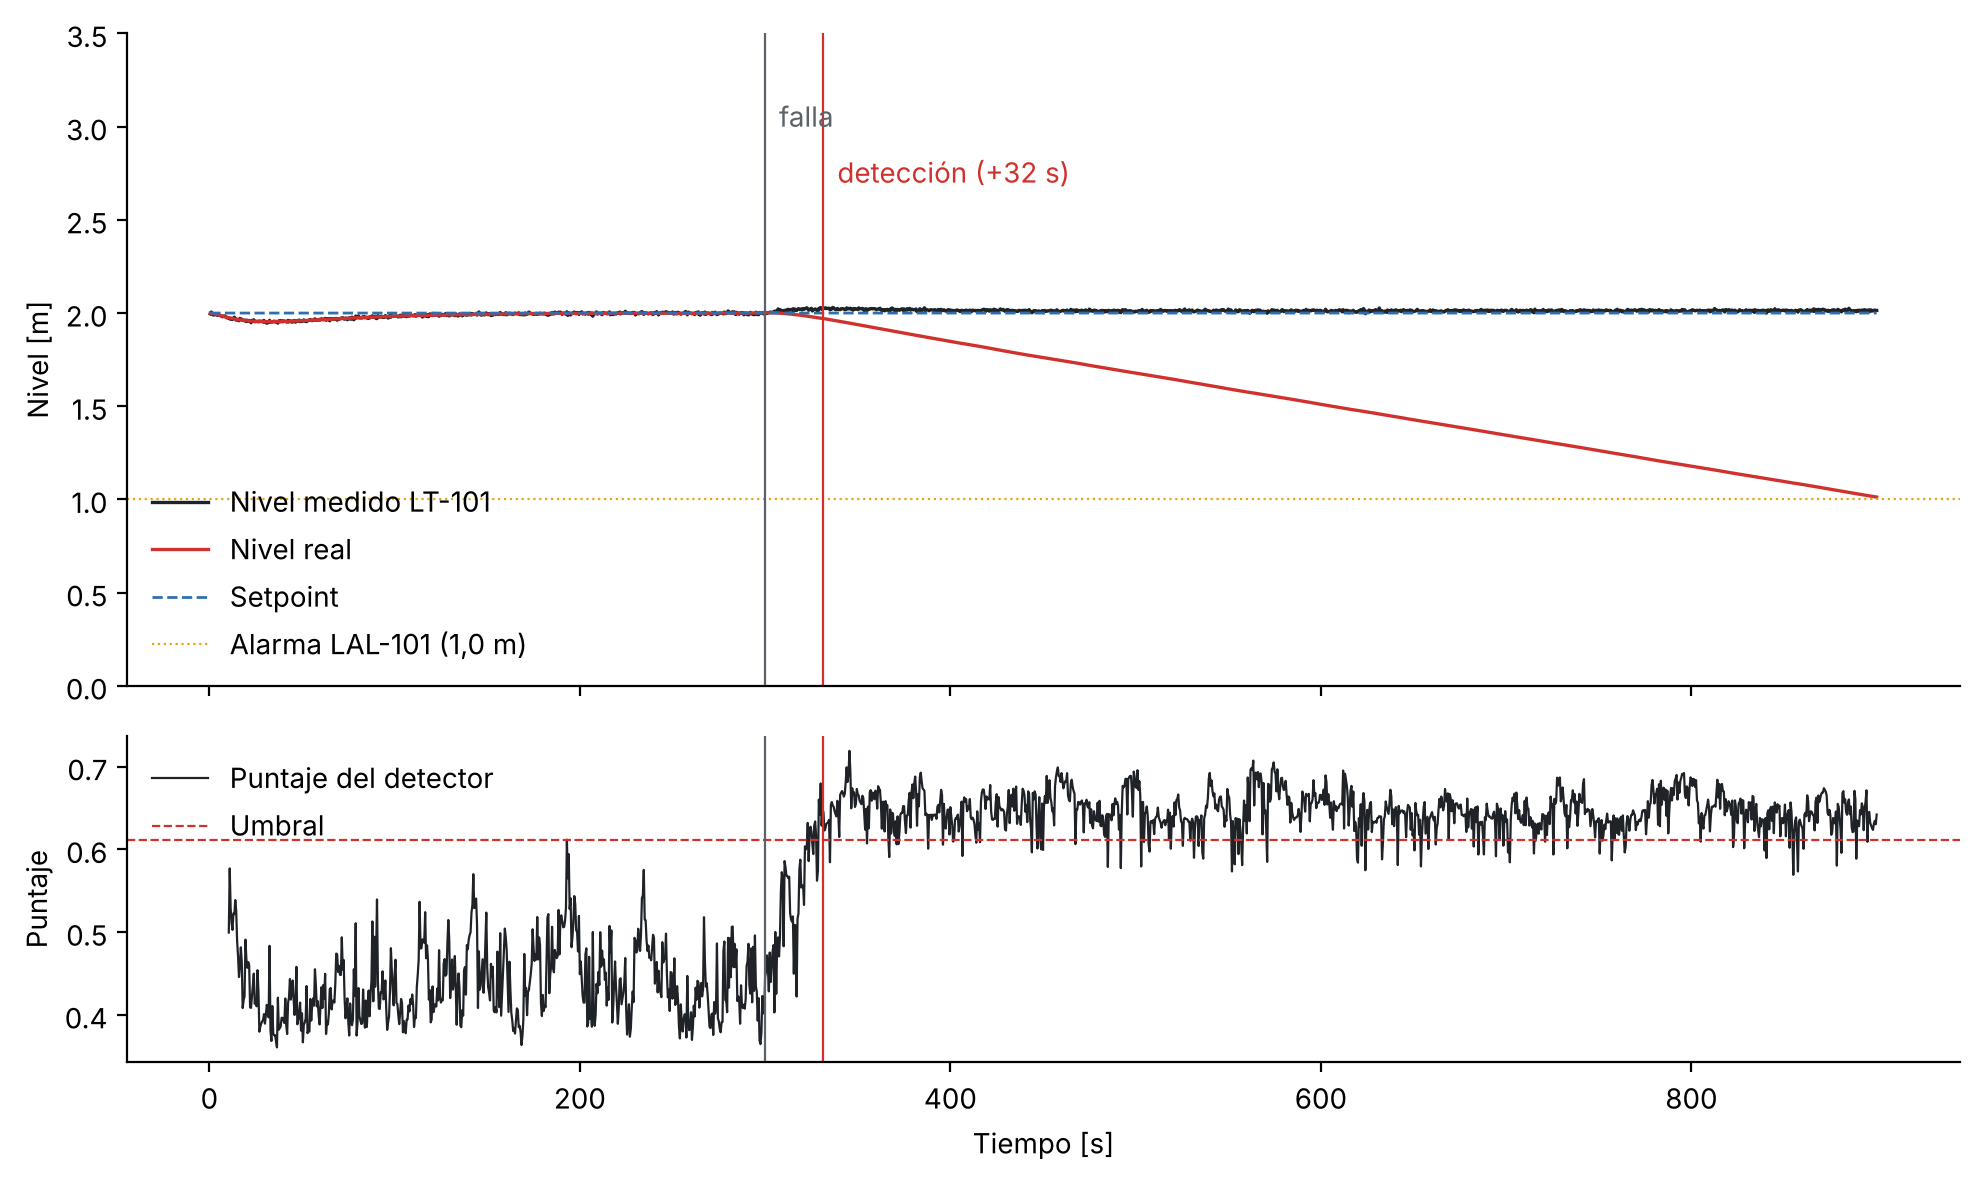

In [4]:
planta, alarmas = Planta(semilla=1003), GestorAlarmas()
detector.reiniciar()
planta.fijar_apertura(60)
filas, t_falla, t_det = [], None, None
while planta.t < 900:
    if t_falla is None and planta.t >= 300:
        planta.inyectar_falla("deriva")
        t_falla = planta.t
    m = planta.paso().a_dict()
    r = detector.procesar(m)
    alarmas.evaluar(m)
    if t_falla and t_det is None and r and r.anomalia:
        t_det = planta.t
    filas.append((m["t"], m["nivel"], m["nivel_real"], m["setpoint"], r.puntaje if r else np.nan))

t, medido, real, sp, puntaje = np.array(filas).T
fig, (a1, a2) = plt.subplots(2, 1, figsize=(10, 6), sharex=True, gridspec_kw={"height_ratios": [2, 1]})
a1.plot(t, medido, color="#1f2328", lw=1.2, label="Nivel medido LT-101")
a1.plot(t, real, color="#d0312d", lw=1.2, label="Nivel real")
a1.plot(t, sp, color="#2f6fb0", ls="--", lw=1, label="Setpoint")
a1.axhline(1.0, color="#e8a317", lw=0.8, ls=":", label="Alarma LAL-101 (1,0 m)")
a1.set_ylabel("Nivel [m]")
a1.legend(loc="lower left", frameon=False)
a2.plot(t, puntaje, color="#1f2328", lw=0.8, label="Puntaje del detector")
a2.axhline(detector.umbral, color="#d0312d", ls="--", lw=0.8, label="Umbral")
a2.set_ylabel("Puntaje")
a2.set_xlabel("Tiempo [s]")
a2.legend(loc="upper left", frameon=False)
for ax in (a1, a2):
    ax.axvline(t_falla, color="#5c6368", lw=0.8)
    ax.axvline(t_det, color="#d0312d", lw=0.8)
    ax.spines[["top", "right"]].set_visible(False)
a1.annotate("falla", (t_falla, 3.0), xytext=(5, 0), textcoords="offset points", color="#5c6368")
a1.annotate(f"detección (+{t_det - t_falla:.0f} s)", (t_det, 2.7), xytext=(5, 0), textcoords="offset points", color="#d0312d")
a1.set_ylim(0, 3.5)
fig.tight_layout()
fig.savefig("../docs/caso_deriva.png", dpi=120)
plt.show()

Al final del caso el nivel real está muy por debajo del setpoint mientras el SCADA muestra el valor correcto. El detector lo marca en menos de un minuto porque la presión de descarga, que incluye la columna de agua, ya no cuadra con el nivel que reporta el transmisor.